# 01 — EIA Data Collection

Этот ноутбук собирает базовые данные из **U.S. Energy Information Administration (EIA) Open Data API v2** для проекта по прогнозированию изменения нефтяных запасов и реакции WTI calendar spread.

На этом этапе мы:

1. проверяем Python и виртуальное окружение;
2. находим корень проекта;
3. подключаем `EIAClient`;
4. проверяем соединение с EIA API;
5. загружаем недельные нефтяные данные;
6. загружаем исторические WTI futures F1–F4;
7. считаем изменения запасов;
8. считаем calendar spreads;
9. проверяем качество данных;
10. сохраняем результаты в `data/raw/eia/`.

> API-ключ **не хранится в ноутбуке**. Он должен находиться в `.env` в корне проекта:
>
> `EIA_API_KEY=...`


## 1. Проверка окружения

Ноутбук должен работать из виртуального окружения проекта `.venv` на Python 3.14.

Если здесь отображается другой Python, в VS Code нужно выбрать правильный kernel.


In [1]:
import sys
from pathlib import Path

print("Python version:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)


Python version:
3.12.16 (main, Oct 26 2026, 13:59:40) [Clang 23.1.3 ]

Python executable:
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/.venv/bin/python


Ожидаемый путь к интерпретатору должен содержать примерно:

```text
oil-news-graph/.venv/bin/python
```

Если используется системный Python, сначала выбери kernel проекта.


## 2. Импорт библиотек и поиск корня проекта

Ноутбук может лежать не прямо в папке `notebooks/`, поэтому корень проекта ищем автоматически.

Корнем считаем ближайшую родительскую директорию, где находится папка `src`.


In [2]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt


def find_project_root(start: Path | None = None) -> Path:
    """Ищет ближайшую родительскую папку, содержащую src/."""

    current = (start or Path.cwd()).resolve()

    for candidate in [current, *current.parents]:
        if (candidate / "src").exists():
            return candidate

    raise FileNotFoundError(
        "Не удалось найти корень проекта. "
        "Проверь, что в проекте есть папка src/."
    )


ROOT = find_project_root()

# Добавляем корень проекта в sys.path,
# чтобы Python видел src/data/eia_client.py
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_DIR = ROOT / "data" / "raw" / "eia"
PROCESSED_DIR = ROOT / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Raw data directory:", RAW_DIR)


Project root: /Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph
Raw data directory: /Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia


## 3. Подключение EIA-клиента

Используем готовый файл:

```text
src/data/eia_client.py
```

В нём уже находятся:

- `EIAClient`;
- `EIA_WEEKLY_SERIES`;
- `EIA_WTI_FUTURES_SERIES`.

Если ты только что менял `eia_client.py`, лучше перезапустить kernel перед запуском ноутбука.


In [3]:
from src.data.eia_client import (
    EIAClient,
    EIA_WEEKLY_SERIES,
    EIA_WTI_FUTURES_SERIES,
)

client = EIAClient()

print("EIAClient initialized successfully.")


EIAClient initialized successfully.


## 4. Проверка соединения

Перед массовой загрузкой всегда проверяем:

- читается ли `.env`;
- работает ли API-ключ;
- отвечает ли EIA API;
- доступен ли тестовый petroleum route.


In [4]:
client.test_connection()


True

Если результат:

```text
True
```

— соединение работает.

Если возникает `401` или `403`, проблема обычно в API-ключе.

Если возникает `404`, проблема обычно в route или series ID.


## 5. Период исследования

Основной период проекта начинается с **19 февраля 2015 года**.

Эта дата удобна тем, что совпадает с началом GDELT 2.0, который позже будет использоваться для новостного графа.

Конец периода пока задаём текущей датой исследования.


In [5]:
START_DATE = "2015-02-19"
END_DATE = "2026-11-03"

print("Start:", START_DATE)
print("End:", END_DATE)


Start: 2015-02-19
End: 2026-11-03


## 6. Посмотрим, какие weekly series сейчас настроены

Не создаём `WEEKLY_SERIES` вручную в ноутбуке.

Используем словарь из `eia_client.py`, чтобы не было двух разных версий конфигурации.


In [6]:
EIA_WEEKLY_SERIES


{'crude_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTUS1',
  'frequency': 'weekly'},
 'cushing_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'W_EPC0_SAX_YCUOK_MBBL',
  'frequency': 'weekly'},
 'padd1_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP11',
  'frequency': 'weekly'},
 'padd2_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP21',
  'frequency': 'weekly'},
 'padd3_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP31',
  'frequency': 'weekly'},
 'padd4_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP41',
  'frequency': 'weekly'},
 'padd5_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP51',
  'frequency': 'weekly'},
 'crude_production': {'route': 'petroleum/sum/sndw',
  'series': 'WCRFPUS2',
  'frequency': 'weekly'}}

## 7. Сначала тестируем один ряд

Перед `fetch_many()` полезно проверить основной ряд отдельно.

Основной target-source:

**U.S. commercial crude oil stocks excluding SPR**

Series:

```text
WCESTUS1
```


In [7]:
test_crude_stocks = client.fetch_series(
    route="petroleum/stoc/wstk",
    series="WCESTUS1",
    frequency="weekly",
    start="2025-01-01",
    end="2025-03-31",
)

test_crude_stocks.head()


,period,value,series,series_description,units,route,frequency
0,2025-01-03,414642,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly
1,2025-01-10,412680,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly
2,2025-01-17,411663,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly
3,2025-01-24,415126,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly
4,2025-01-31,423790,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly


In [8]:
print("Shape:", test_crude_stocks.shape)
print(
    "Period:",
    test_crude_stocks["period"].min(),
    "->",
    test_crude_stocks["period"].max(),
)


Shape: (13, 7)
Period: 2025-01-03 00:00:00 -> 2025-03-28 00:00:00


Если здесь появилась таблица, можно переходить к полной weekly-загрузке.


# 8. Загрузка weekly EIA data

Загружаем все серии, которые сейчас находятся в `EIA_WEEKLY_SERIES`.

На первом этапе это:

- commercial crude stocks;
- Cushing stocks;
- PADD 1–5 stocks;
- U.S. crude production.

Позже словарь можно расширять imports, exports, refinery inputs, refinery utilization, gasoline, distillates и другими фундаментальными рядами.


In [9]:
weekly = client.fetch_many(
    series=EIA_WEEKLY_SERIES,
    start=START_DATE,
    end=END_DATE,
)

weekly.head()


,period,crude_stocks,cushing_stocks,padd1_stocks,padd2_stocks,padd3_stocks,padd4_stocks,padd5_stocks,crude_production
0,2015-02-20,399943,48680,16819,123417,192085,16502,51119,9285
1,2015-02-27,410246,49216,16450,126691,197474,16381,53250,9324
2,2015-03-06,415425,51538,16018,128637,200461,16504,53805,9366
3,2015-03-13,425047,54403,16312,131751,203731,17129,56123,9419
4,2015-03-20,433217,56314,15682,136448,205293,18058,57736,9422


In [10]:
print("Shape:", weekly.shape)

print(
    "Period:",
    weekly["period"].min(),
    "->",
    weekly["period"].max(),
)


Shape: (610, 9)
Period: 2015-02-20 00:00:00 -> 2026-10-23 00:00:00


## 9. Проверка weekly dataset

Смотрим:

- типы данных;
- пропуски;
- дубликаты дат;
- последние наблюдения.


In [11]:
weekly.info()


<class 'pandas.DataFrame'>
RangeIndex: 610 entries, 0 to 609
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   period            610 non-null    datetime64[us]
 1   crude_stocks      610 non-null    int64         
 2   cushing_stocks    610 non-null    int64         
 3   padd1_stocks      610 non-null    int64         
 4   padd2_stocks      610 non-null    int64         
 5   padd3_stocks      610 non-null    int64         
 6   padd4_stocks      610 non-null    int64         
 7   padd5_stocks      610 non-null    int64         
 8   crude_production  610 non-null    int64         
dtypes: datetime64[us](1), int64(8)
memory usage: 43.0 KB


In [12]:
weekly.tail(10)


,period,crude_stocks,cushing_stocks,padd1_stocks,padd2_stocks,padd3_stocks,padd4_stocks,padd5_stocks,crude_production
600,2026-08-21,428910,22428,8423,101195,251424,22524,45343,13843
601,2026-08-28,424460,22508,8534,100484,245061,22714,47667,13862
602,2026-09-04,424069,21824,8388,100103,247488,23112,44979,13947
603,2026-09-11,423429,21482,8195,99663,246172,23409,45989,13944
604,2026-09-18,426398,23748,8372,104070,244080,23319,46558,13939
605,2026-09-25,427320,24301,7994,105110,247497,22496,44224,13955
606,2026-10-02,424134,24745,7744,106981,243599,22352,43458,13979
607,2026-10-09,415577,26607,7413,107004,234359,22710,44091,13679
608,2026-10-16,412517,27594,8550,107639,229318,23496,43513,13269
609,2026-10-23,410625,26970,8032,107884,227776,24915,42019,13992


In [13]:
weekly.isna().sum().sort_values(ascending=False)


period              0
crude_stocks        0
cushing_stocks      0
padd1_stocks        0
padd2_stocks        0
padd3_stocks        0
padd4_stocks        0
padd5_stocks        0
crude_production    0
dtype: int64

In [14]:
duplicate_dates = weekly["period"].duplicated().sum()

print("Duplicated dates:", duplicate_dates)

assert duplicate_dates == 0, "В weekly dataset есть дубликаты дат."


Duplicated dates: 0


## 10. Проверка недельных интервалов

Большинство соседних observation dates должны отличаться примерно на 7 дней.

Отдельные отклонения могут появляться из-за особенностей публикации или структуры ряда, поэтому их не удаляем автоматически.


In [15]:
weekly_intervals = weekly["period"].diff().dt.days

weekly_intervals.value_counts().sort_index()


period
7.0    609
Name: count, dtype: int64

# 11. Подготовка запасов

EIA stock series обычно выражены в **thousand barrels**.

Для дальнейшей работы удобнее также иметь значения в **million barrels (MMbbl)**.

Перевод:

```text
1 MMbbl = 1000 thousand barrels
```


In [16]:
weekly_features = weekly.copy()

stock_columns = [
    col
    for col in [
        "crude_stocks",
        "cushing_stocks",
        "padd1_stocks",
        "padd2_stocks",
        "padd3_stocks",
        "padd4_stocks",
        "padd5_stocks",
    ]
    if col in weekly_features.columns
]

for col in stock_columns:
    weekly_features[f"{col}_mmbbl"] = (
        weekly_features[col] / 1000
    )

stock_columns


['crude_stocks',
 'cushing_stocks',
 'padd1_stocks',
 'padd2_stocks',
 'padd3_stocks',
 'padd4_stocks',
 'padd5_stocks']

## 12. Изменение коммерческих запасов

Наш будущий target связан не с уровнем запасов, а с **еженедельным изменением запасов**.

Сначала считаем фактическое изменение:

```text
Actual Δ Stocks_t = Stocks_t - Stocks_(t-1)
```

Позже, когда добавим analyst consensus:

```text
Inventory Surprise_t =
Actual Δ Stocks_t - Consensus_t
```


In [17]:
if "crude_stocks_mmbbl" in weekly_features.columns:
    weekly_features["crude_stocks_change_mmbbl"] = (
        weekly_features["crude_stocks_mmbbl"].diff()
    )

if "cushing_stocks_mmbbl" in weekly_features.columns:
    weekly_features["cushing_change_mmbbl"] = (
        weekly_features["cushing_stocks_mmbbl"].diff()
    )

for padd in range(1, 6):
    col = f"padd{padd}_stocks_mmbbl"

    if col in weekly_features.columns:
        weekly_features[f"padd{padd}_change_mmbbl"] = (
            weekly_features[col].diff()
        )


In [18]:
cols_to_show = [
    col
    for col in [
        "period",
        "crude_stocks_mmbbl",
        "crude_stocks_change_mmbbl",
        "cushing_stocks_mmbbl",
        "cushing_change_mmbbl",
        "crude_production",
    ]
    if col in weekly_features.columns
]

weekly_features[cols_to_show].tail(10)


,period,crude_stocks_mmbbl,crude_stocks_change_mmbbl,cushing_stocks_mmbbl,cushing_change_mmbbl,crude_production
600,2026-08-21,428.910,0.095,22.428,1.176,13843
601,2026-08-28,424.460,-4.450,22.508,0.080,13862
602,2026-09-04,424.069,-0.391,21.824,-0.684,13947
603,2026-09-11,423.429,-0.640,21.482,-0.342,13944
604,2026-09-18,426.398,2.969,23.748,2.266,13939
605,2026-09-25,427.320,0.922,24.301,0.553,13955
606,2026-10-02,424.134,-3.186,24.745,0.444,13979
607,2026-10-09,415.577,-8.557,26.607,1.862,13679
608,2026-10-16,412.517,-3.060,27.594,0.987,13269
609,2026-10-23,410.625,-1.892,26.970,-0.624,13992


## 13. Визуальная проверка commercial crude stocks


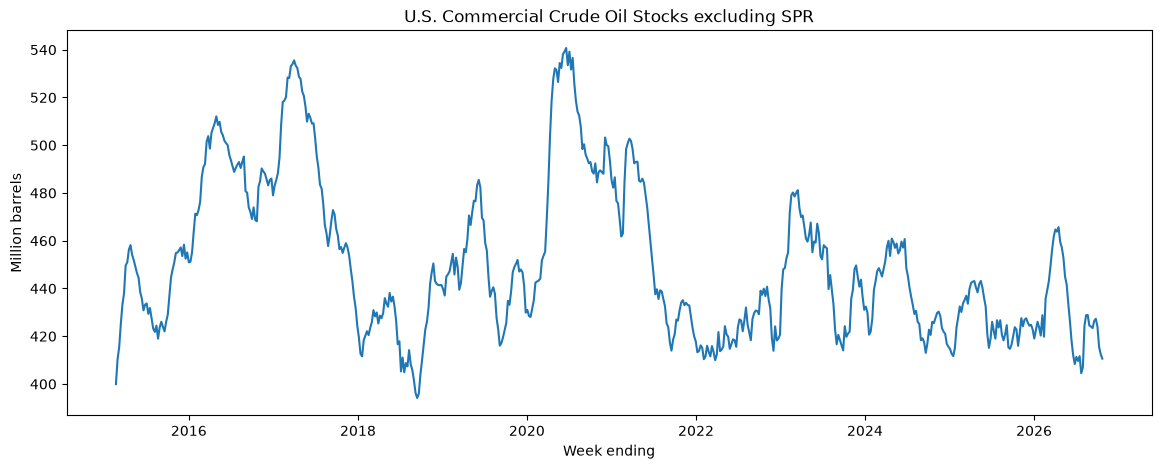

In [19]:
if "crude_stocks_mmbbl" in weekly_features.columns:
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        weekly_features["period"],
        weekly_features["crude_stocks_mmbbl"],
    )

    ax.set_title(
        "U.S. Commercial Crude Oil Stocks excluding SPR"
    )
    ax.set_xlabel("Week ending")
    ax.set_ylabel("Million barrels")

    plt.show()


# 14. Загрузка исторических WTI futures

EIA публиковала ежедневные цены первых четырёх последовательных WTI futures contracts:

- `RCLC1` → F1;
- `RCLC2` → F2;
- `RCLC3` → F3;
- `RCLC4` → F4.

Для стратегии нас интересует не столько абсолютная цена WTI, сколько **calendar spread**:

```text
Spread = F_near - F_far
```

Например:

```text
F1 - F3
```

Интерпретация:

- spread > 0 → backwardation;
- spread < 0 → contango.


In [20]:
EIA_WTI_FUTURES_SERIES


{'wti_f1': {'route': 'petroleum/pri/fut',
  'series': 'RCLC1',
  'frequency': 'daily'},
 'wti_f2': {'route': 'petroleum/pri/fut',
  'series': 'RCLC2',
  'frequency': 'daily'},
 'wti_f3': {'route': 'petroleum/pri/fut',
  'series': 'RCLC3',
  'frequency': 'daily'},
 'wti_f4': {'route': 'petroleum/pri/fut',
  'series': 'RCLC4',
  'frequency': 'daily'}}

## 15. Сначала проверяем один futures series


In [21]:
test_f1 = client.fetch_series(
    route="petroleum/pri/fut",
    series="RCLC1",
    frequency="daily",
    start="2024-01-01",
    end="2024-04-30",
)

test_f1.tail()


,period,value,series,series_description,units,route,frequency
61,2024-04-01,83.71,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily
62,2024-04-02,85.15,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily
63,2024-04-03,85.43,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily
64,2024-04-04,86.59,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily
65,2024-04-05,86.91,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily


In [22]:
print("F1 observations:", len(test_f1))

if not test_f1.empty:
    print(
        "F1 period:",
        test_f1["period"].min(),
        "->",
        test_f1["period"].max(),
    )


F1 observations: 66
F1 period: 2024-01-02 00:00:00 -> 2024-04-05 00:00:00


Исторические futures series EIA заканчиваются раньше текущего периода проекта.

Это нормально: данные EIA F1–F4 будем использовать для бесплатного исторического EDA, а более поздний период позже дополним отдельным источником.


## 16. Загружаем F1–F4


In [23]:
futures = client.fetch_many(
    series=EIA_WTI_FUTURES_SERIES,
    start=START_DATE,
    end=END_DATE,
)

futures.head()


,period,wti_f1,wti_f2,wti_f3,wti_f4
0,2015-02-19,51.16,51.83,53.00,54.22
1,2015-02-20,50.34,50.81,52.09,53.45
2,2015-02-23,49.45,51.01,52.56,54.06
3,2015-02-24,49.28,50.83,52.34,53.79
4,2015-02-25,50.99,52.76,54.31,55.77


In [24]:
print("Shape:", futures.shape)

print(
    "Period:",
    futures["period"].min(),
    "->",
    futures["period"].max(),
)


Shape: (2305, 5)
Period: 2015-02-19 00:00:00 -> 2024-04-05 00:00:00


In [25]:
futures.tail(10)


,period,wti_f1,wti_f2,wti_f3,wti_f4
2295,2024-03-22,80.63,80.17,79.61,78.95
2296,2024-03-25,81.95,81.38,80.77,80.06
2297,2024-03-26,81.62,81.04,80.43,79.73
2298,2024-03-27,81.35,80.78,80.19,79.52
2299,2024-03-28,83.17,82.42,81.67,80.89
2300,2024-04-01,83.71,82.82,81.98,81.12
2301,2024-04-02,85.15,84.22,83.29,82.34
2302,2024-04-03,85.43,84.61,83.77,82.88
2303,2024-04-04,86.59,85.81,84.96,84.03
2304,2024-04-05,86.91,86.10,85.20,84.24


# 17. Calendar spreads

Считаем:

```text
F1-F2
F1-F3
F1-F4
```

Для основной гипотезы сначала особенно интересен `F1-F3`.

Мы используем соглашение:

```text
spread = near contract - far contract
```


In [26]:
futures_features = futures.copy()

required_pairs = [
    ("wti_f1", "wti_f2", "spread_1_2"),
    ("wti_f1", "wti_f3", "spread_1_3"),
    ("wti_f1", "wti_f4", "spread_1_4"),
]

for near_col, far_col, spread_col in required_pairs:
    if (
        near_col in futures_features.columns
        and far_col in futures_features.columns
    ):
        futures_features[spread_col] = (
            futures_features[near_col]
            - futures_features[far_col]
        )

futures_features.tail()


,period,wti_f1,wti_f2,wti_f3,wti_f4,spread_1_2,spread_1_3,spread_1_4
2300,2024-04-01,83.71,82.82,81.98,81.12,0.89,1.73,2.59
2301,2024-04-02,85.15,84.22,83.29,82.34,0.93,1.86,2.81
2302,2024-04-03,85.43,84.61,83.77,82.88,0.82,1.66,2.55
2303,2024-04-04,86.59,85.81,84.96,84.03,0.78,1.63,2.56
2304,2024-04-05,86.91,86.10,85.20,84.24,0.81,1.71,2.67


## 18. Изменение spread

Позже будем сопоставлять surprise в запасах с изменением кривой WTI.

Поэтому считаем:

```text
ΔSpread_t = Spread_t - Spread_(t-1)
```


In [27]:
spread_columns = [
    col
    for col in [
        "spread_1_2",
        "spread_1_3",
        "spread_1_4",
    ]
    if col in futures_features.columns
]

for col in spread_columns:
    futures_features[f"delta_{col}"] = (
        futures_features[col].diff()
    )

futures_features.tail()


,period,wti_f1,wti_f2,wti_f3,wti_f4,spread_1_2,spread_1_3,spread_1_4,delta_spread_1_2,delta_spread_1_3,delta_spread_1_4
2300,2024-04-01,83.71,82.82,81.98,81.12,0.89,1.73,2.59,0.14,0.23,0.31
2301,2024-04-02,85.15,84.22,83.29,82.34,0.93,1.86,2.81,0.04,0.13,0.22
2302,2024-04-03,85.43,84.61,83.77,82.88,0.82,1.66,2.55,-0.11,-0.20,-0.26
2303,2024-04-04,86.59,85.81,84.96,84.03,0.78,1.63,2.56,-0.04,-0.03,0.01
2304,2024-04-05,86.91,86.10,85.20,84.24,0.81,1.71,2.67,0.03,0.08,0.11


## 19. Визуальная проверка F1-F3 spread


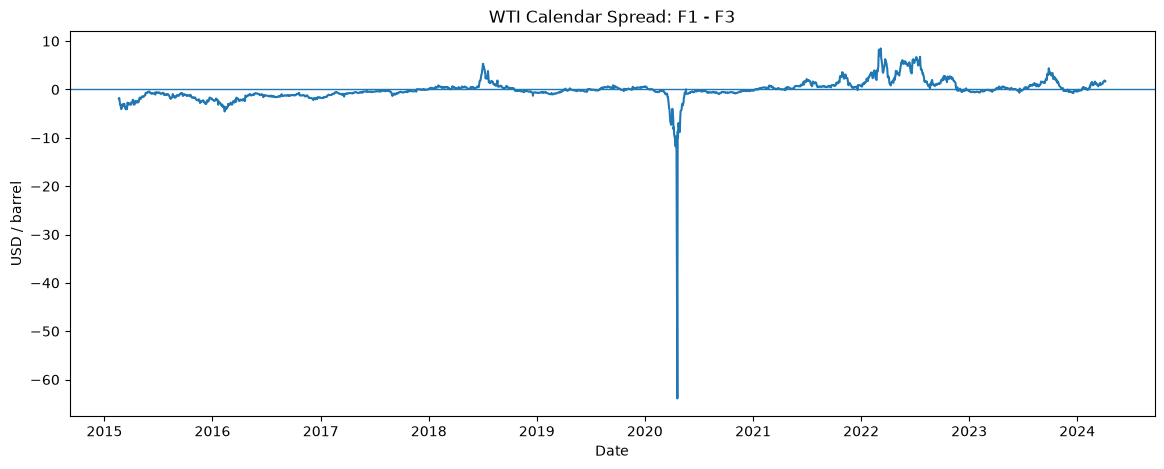

In [28]:
if "spread_1_3" in futures_features.columns:
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        futures_features["period"],
        futures_features["spread_1_3"],
    )

    ax.axhline(0, linewidth=1)

    ax.set_title(
        "WTI Calendar Spread: F1 - F3"
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("USD / barrel")

    plt.show()


# 20. Функция для быстрого контроля качества

Эта таблица показывает:

- dtype;
- количество пропусков;
- процент пропусков;
- число уникальных значений.


In [29]:
def data_summary(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "dtype": df.dtypes.astype(str),
            "missing": df.isna().sum(),
            "missing_pct": (
                df.isna().mean() * 100
            ).round(2),
            "n_unique": df.nunique(dropna=True),
        }
    )


data_summary(weekly_features)


,dtype,missing,missing_pct,n_unique
period,datetime64[us],0,0.00,610
crude_stocks,int64,0,0.00,609
cushing_stocks,int64,0,0.00,610
padd1_stocks,int64,0,0.00,593
padd2_stocks,int64,0,0.00,602
padd3_stocks,int64,0,0.00,609
padd4_stocks,int64,0,0.00,581
padd5_stocks,int64,0,0.00,596
crude_production,int64,0,0.00,290
crude_stocks_mmbbl,float64,0,0.00,609


In [30]:
data_summary(futures_features)


,dtype,missing,missing_pct,n_unique
period,datetime64[us],0,0.00,2305
wti_f1,float64,0,0.00,1912
wti_f2,float64,0,0.00,1906
wti_f3,float64,0,0.00,1865
wti_f4,float64,0,0.00,1882
spread_1_2,float64,0,0.00,666
spread_1_3,float64,0,0.00,978
spread_1_4,float64,0,0.00,1151
delta_spread_1_2,float64,1,0.04,344
delta_spread_1_3,float64,1,0.04,470


# 21. Сохранение данных

Сохраняем как:

- CSV — удобно быстро открыть глазами;
- Parquet — основной формат для дальнейшего Python pipeline.

Большие файлы из `data/raw/` обычно **не пушим в Git**.


In [31]:
weekly_csv = RAW_DIR / "eia_weekly_2015_2026.csv"
weekly_parquet = RAW_DIR / "eia_weekly_2015_2026.parquet"

weekly_features.to_csv(
    weekly_csv,
    index=False,
)

weekly_features.to_parquet(
    weekly_parquet,
    index=False,
)

print("Saved:")
print(weekly_csv)
print(weekly_parquet)


Saved:
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia/eia_weekly_2015_2026.csv
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia/eia_weekly_2015_2026.parquet


In [32]:
futures_csv = RAW_DIR / "eia_wti_futures_2015_2024.csv"
futures_parquet = RAW_DIR / "eia_wti_futures_2015_2024.parquet"

futures_features.to_csv(
    futures_csv,
    index=False,
)

futures_features.to_parquet(
    futures_parquet,
    index=False,
)

print("Saved:")
print(futures_csv)
print(futures_parquet)


Saved:
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia/eia_wti_futures_2015_2024.csv
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia/eia_wti_futures_2015_2024.parquet


# 22. Итог текущего этапа

После успешного выполнения ноутбука у нас есть два основных блока данных.

### Weekly fundamentals

Примерно:

```text
data/raw/eia/eia_weekly_2015_2026.parquet
```

Содержит:

- commercial crude stocks;
- Cushing stocks;
- PADD stocks;
- production;
- производные weekly changes.

### WTI futures

```text
data/raw/eia/eia_wti_futures_2015_2024.parquet
```

Содержит:

- F1;
- F2;
- F3;
- F4;
- F1-F2;
- F1-F3;
- F1-F4;
- изменения spreads.

---

## Что пока НЕ делаем

В этом ноутбуке пока нет:

1. analyst consensus;
2. точного EIA `release_datetime`;
3. API Weekly Statistical Bulletin;
4. новостей;
5. графа;
6. merge fundamentals + consensus + market reaction.

Это будут отдельные этапы, чтобы не смешивать сбор разных источников в одном ноутбуке.

Следующий логичный шаг после проверки этого ноутбука — расширить `EIA_WEEKLY_SERIES` корректными native API v2 routes для:

- imports;
- exports;
- refinery inputs;
- refinery utilization;
- gasoline stocks;
- distillate stocks;
- SPR;
- products supplied.
